# Refresca · Previsão de dias de calor perigoso

**Global Solution 2026.2 · Inteligência Artificial & Machine Learning**

**Pergunta de ML:** com os dados do clima de hoje, amanhã será um dia de calor perigoso em São Paulo?

**Por que importa:** trabalhadores de rua da Vila Mariana passam o dia expostos ao sol. Se a Refresca souber na véspera que o dia vai ser perigoso, o app avisa o trabalhador para levar água e planejar pausas na sombra.

**Dados:** dados históricos horários reais do INMET, estação automática A701 (São Paulo, Mirante de Santana). Fonte, link e período em `dados/README.md`.

**Roteiro do notebook**

1. Obter e carregar os dados do INMET
2. Limpar e conferir a qualidade
3. Calcular o índice de calor e agregar por dia
4. Definir o rótulo e as variáveis
5. Dividir treino e teste respeitando o tempo
6. Treinar o XGBoost com 48 combinações de hiperparâmetros (validação cruzada só no treino) e escolher o limiar do alerta
7. Avaliar treino e teste lado a lado e discutir overfitting
8. Concluir o que o resultado significa para o trabalhador
9. Salvar o modelo para o serviço de previsão
10. Conferir o módulo usado pelo serviço de previsão

In [1]:
import json
import re
import unicodedata
import zipfile
from pathlib import Path
from urllib.request import urlopen

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBClassifier

SEMENTE = 42
np.random.seed(SEMENTE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.1


## 1. Obter os dados do INMET

O INMET publica um ZIP por ano com todas as estações automáticas do Brasil. A célula abaixo baixa os anos configurados e guarda **só** o CSV da estação A701 em `dados/brutos/`. Se um ano já estiver lá, ela não baixa de novo.

Se o download automático falhar (o site do INMET às vezes fica fora do ar), baixe os ZIPs manualmente em <https://portal.inmet.gov.br/dadoshistoricos> e coloque os CSVs da A701 em `dados/brutos/`.

In [2]:
ESTACAO = "A701"
ANOS = list(range(2019, 2026))
PASTA_BRUTOS = Path("dados/brutos")
PASTA_BRUTOS.mkdir(parents=True, exist_ok=True)
URL_ZIP = "https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"


def csv_da_estacao_no_disco(ano):
    # Nome do INMET: INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2024_A_31-12-2024.CSV
    for arquivo in PASTA_BRUTOS.iterdir():
        nome = arquivo.name.upper()
        if nome.endswith(".CSV") and f"_{ESTACAO}_" in nome and f"-{ano}_" in nome:
            return arquivo
    return None


def baixar_ano(ano):
    zip_temp = PASTA_BRUTOS / f"{ano}.zip"
    with urlopen(URL_ZIP.format(ano=ano), timeout=120) as resposta, open(zip_temp, "wb") as saida:
        while bloco := resposta.read(1 << 20):
            saida.write(bloco)
    with zipfile.ZipFile(zip_temp) as z:
        membros = [m for m in z.namelist() if f"_{ESTACAO}_" in m.upper()]
        for membro in membros:
            (PASTA_BRUTOS / Path(membro).name).write_bytes(z.read(membro))
    zip_temp.unlink()


for ano in ANOS:
    if csv_da_estacao_no_disco(ano):
        print(f"{ano}: já está em {PASTA_BRUTOS}")
        continue
    try:
        print(f"{ano}: baixando do INMET...")
        baixar_ano(ano)
        print(f"{ano}: ok")
    except Exception as erro:
        print(f"{ano}: falhou ({erro}). Baixe manualmente e coloque o CSV da {ESTACAO} em {PASTA_BRUTOS}.")

arquivos = sorted(f for f in PASTA_BRUTOS.iterdir() if f.suffix.lower() == ".csv" and f"_{ESTACAO}_" in f.name.upper())
print(f"\n{len(arquivos)} arquivo(s) da estação {ESTACAO}:")
for f in arquivos:
    print(" -", f.name)
assert arquivos, "Nenhum CSV da estação encontrado em dados/brutos/."

2019: já está em dados/brutos
2020: já está em dados/brutos
2021: já está em dados/brutos
2022: já está em dados/brutos
2023: já está em dados/brutos
2024: já está em dados/brutos
2025: já está em dados/brutos

7 arquivo(s) da estação A701:
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2019_A_31-12-2019.CSV
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2020_A_31-12-2020.CSV
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2021_A_31-12-2021.CSV
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2022_A_31-12-2022.CSV
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2023_A_31-12-2023.CSV
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2024_A_31-12-2024.CSV
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2025_A_31-12-2025.CSV


## 2. Carregar e limpar

Particularidades dos CSVs do INMET que o código trata:

- 8 linhas de metadados da estação antes do cabeçalho;
- separador `;`, vírgula como decimal e codificação latin-1;
- `-9999` significa medição ausente;
- os nomes das colunas de data e hora mudam a partir de 2019 (`Data` e `Hora UTC` em vez de `DATA (YYYY-MM-DD)` e `HORA (UTC)`);
- o horário é UTC e precisa ser convertido para o horário de Brasília para agregar os dias corretamente.

In [3]:
def normalizar(texto):
    sem_acento = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", sem_acento).strip().upper()


REGRAS_COLUNAS = {
    "temp": lambda c: "BULBO SECO" in c,
    "temp_max_hora": lambda c: c.startswith("TEMPERATURA MAXIMA NA HORA"),
    "temp_min_hora": lambda c: c.startswith("TEMPERATURA MINIMA NA HORA"),
    "orvalho": lambda c: c.startswith("TEMPERATURA DO PONTO DE ORVALHO"),
    "umidade": lambda c: c.startswith("UMIDADE RELATIVA DO AR"),
    "umid_min_hora": lambda c: c.startswith("UMIDADE REL. MIN"),
    "pressao": lambda c: c.startswith("PRESSAO ATMOSFERICA AO NIVEL"),
    "radiacao": lambda c: c.startswith("RADIACAO"),
    "precip": lambda c: c.startswith("PRECIPITACAO"),
    "vento": lambda c: c.startswith("VENTO, VELOCIDADE"),
}


def ler_csv_inmet(caminho):
    with open(caminho, encoding="latin-1") as f:
        linhas = f.readlines()
    inicio = next(i for i, l in enumerate(linhas) if normalizar(l).startswith("DATA") and ";HORA" in normalizar(l))
    df = pd.read_csv(
        caminho, sep=";", decimal=",", encoding="latin-1", skiprows=inicio,
        na_values=["-9999", "-9999,0", -9999], low_memory=False,
    )
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    originais = {normalizar(c): c for c in df.columns}

    col_data = next(o for n, o in originais.items() if n.startswith("DATA"))
    col_hora = next(o for n, o in originais.items() if n.startswith("HORA"))
    saida = pd.DataFrame()
    hora = df[col_hora].astype(str).str.replace(" UTC", "", regex=False).str.replace(":", "", regex=False).str.zfill(4)
    data = df[col_data].astype(str).str.replace("/", "-", regex=False)
    saida["momento_utc"] = pd.to_datetime(data + " " + hora.str[:2] + ":" + hora.str[2:], format="%Y-%m-%d %H:%M", utc=True)

    for nome, regra in REGRAS_COLUNAS.items():
        candidatas = [o for n, o in originais.items() if regra(n)]
        saida[nome] = pd.to_numeric(df[candidatas[0]], errors="coerce") if candidatas else np.nan
    return saida


horario = pd.concat([ler_csv_inmet(f) for f in arquivos], ignore_index=True)
horario = horario.drop_duplicates("momento_utc").sort_values("momento_utc")
horario["momento"] = horario["momento_utc"].dt.tz_convert("America/Sao_Paulo")
horario["dia"] = horario["momento"].dt.date

print(f"{len(horario):,} registros horários de {horario['momento'].min():%d/%m/%Y} a {horario['momento'].max():%d/%m/%Y}")
horario.head()

61,368 registros horários de 31/12/2018 a 31/12/2025


,momento_utc,temp,temp_max_hora,temp_min_hora,orvalho,umidade,umid_min_hora,pressao,radiacao,precip,vento,momento,dia
0,2019-01-01 00:00:00+00:00,22.8,23.0,22.7,16.9,69.0,68.0,925.6,NaN,0.0,2.6,2018-12-31 22:00:00-02:00,2018-12-31
1,2019-01-01 01:00:00+00:00,22.3,22.8,22.3,16.8,71.0,68.0,926.0,NaN,0.0,2.5,2018-12-31 23:00:00-02:00,2018-12-31
2,2019-01-01 02:00:00+00:00,22.1,22.3,22.1,17.0,73.0,71.0,925.5,NaN,0.0,2.1,2019-01-01 00:00:00-02:00,2019-01-01
3,2019-01-01 03:00:00+00:00,21.6,22.1,21.6,17.1,76.0,73.0,924.7,NaN,0.0,1.6,2019-01-01 01:00:00-02:00,2019-01-01
4,2019-01-01 04:00:00+00:00,21.6,21.6,21.5,17.1,76.0,75.0,924.4,NaN,0.0,2.2,2019-01-01 02:00:00-02:00,2019-01-01


In [4]:
faltantes = horario.drop(columns=["momento_utc", "momento", "dia"]).isna().mean().mul(100).round(1)
print("Percentual de horas sem medição, por variável:")
print(faltantes.sort_values(ascending=False).to_string())

# Valores fisicamente impossíveis viram ausentes
horario.loc[~horario["temp"].between(-5, 45), "temp"] = np.nan
horario.loc[~horario["temp_max_hora"].between(-5, 45), "temp_max_hora"] = np.nan
horario.loc[~horario["umidade"].between(1, 100), "umidade"] = np.nan
horario.loc[horario["radiacao"] < 0, "radiacao"] = 0

Percentual de horas sem medição, por variável:
radiacao         47.3
precip            1.2
temp_max_hora     0.5
temp              0.5
temp_min_hora     0.5
orvalho           0.5
umid_min_hora     0.5
umidade           0.5
pressao           0.5
vento             0.5


## 3. Índice de calor e agregação diária

O **índice de calor** combina temperatura e umidade para estimar a sensação térmica do corpo. Usamos a fórmula de Rothfusz, adotada pelo serviço meteorológico dos EUA (NOAA), com os ajustes oficiais para umidade baixa e alta. Abaixo de cerca de 27 °C, o índice é praticamente igual à temperatura.

Depois, as medições horárias viram um registro por dia. Dias com menos de 18 horas medidas são descartados, para não criar máximos falsos.

In [5]:
def indice_de_calor(temp_c, umidade):
    t = temp_c * 9 / 5 + 32
    rh = umidade
    simples = 0.5 * (t + 61.0 + (t - 68.0) * 1.2 + rh * 0.094)
    hi = (
        -42.379 + 2.04901523 * t + 10.14333127 * rh - 0.22475541 * t * rh
        - 0.00683783 * t**2 - 0.05481717 * rh**2 + 0.00122874 * t**2 * rh
        + 0.00085282 * t * rh**2 - 0.00000199 * t**2 * rh**2
    )
    ajuste_seco = np.where((rh < 13) & (t >= 80) & (t <= 112), ((13 - rh) / 4) * np.sqrt(np.clip(17 - np.abs(t - 95), 0, None) / 17), 0)
    ajuste_umido = np.where((rh > 85) & (t >= 80) & (t <= 87), ((rh - 85) / 10) * ((87 - t) / 5), 0)
    hi = hi - ajuste_seco + ajuste_umido
    resultado_f = np.where((simples + t) / 2 < 80, simples, hi)
    return (resultado_f - 32) * 5 / 9


horario["indice_calor"] = indice_de_calor(horario["temp"], horario["umidade"])

diario = horario.groupby("dia").agg(
    horas=("temp", "count"),
    temp_max=("temp_max_hora", "max"),
    temp_min=("temp", "min"),
    temp_media=("temp", "mean"),
    umid_media=("umidade", "mean"),
    umid_min=("umidade", "min"),
    ic_max=("indice_calor", "max"),
    pressao_media=("pressao", "mean"),
    radiacao_total=("radiacao", "sum"),
    precip_total=("precip", "sum"),
    vento_medio=("vento", "mean"),
)
diario["temp_max"] = diario["temp_max"].fillna(horario.groupby("dia")["temp"].max())
diario.index = pd.to_datetime(diario.index)
dias_antes = len(diario)
diario = diario[diario["horas"] >= 18].drop(columns="horas")
print(f"{len(diario):,} dias completos (descartados {dias_antes - len(diario)} dias com menos de 18 horas medidas)")
diario.describe().round(1)

2,542 dias completos (descartados 16 dias com menos de 18 horas medidas)


,temp_max,temp_min,temp_media,umid_media,umid_min,ic_max,pressao_media,radiacao_total,precip_total,vento_medio
count,2542.0,2542.0,2542.0,2542.0,2542.0,2542.0,2542.0,2542.0,2542.0,2542.0
mean,26.8,17.0,20.7,68.1,44.4,25.8,927.2,17029.9,4.3,1.7
std,4.5,3.1,3.4,10.8,15.4,4.4,3.4,6182.7,11.0,0.7
min,12.0,4.4,8.2,28.3,12.0,10.6,915.0,1359.1,0.0,0.0
25%,24.0,14.9,18.4,62.3,33.0,23.0,924.8,13265.8,0.0,1.3
50%,27.2,17.2,20.9,69.2,43.0,26.3,926.9,17816.8,0.0,1.7
75%,30.1,19.4,23.2,75.3,54.8,29.1,929.4,21429.8,2.2,2.1
max,37.5,24.6,31.0,94.1,91.0,35.5,938.2,31668.2,142.4,6.1


## 4. Rótulo e variáveis

**Rótulo:** um dia é **perigoso** quando o índice de calor máximo chega a **32 °C ou mais**. Pela NOAA, a partir desse valor a exposição prolongada entra na faixa de "cuidado extremo", com risco de cãibras e exaustão pelo calor. É o mesmo limite que o totem e o app da Refresca usam para o nível "perigo".

**Alvo:** se **amanhã** será perigoso. Cada linha usa só informações disponíveis até o fim de hoje, então o modelo nunca vê o futuro.

**Variáveis:**

- clima de hoje (temperaturas, umidade, índice de calor, pressão, radiação, chuva, vento);
- valores de 1 e 2 dias antes, e médias dos últimos 3 dias, para capturar ondas de calor;
- variação da pressão e da temperatura máxima em relação a ontem;
- época do ano, codificada como seno e cosseno do dia do ano (o fim de dezembro fica perto do começo de janeiro).

In [6]:
LIMITE_PERIGO = 32.0

dados = diario.asfreq("D")  # dias faltantes viram linhas vazias, para os atrasos não pularem datas
dados["perigoso_hoje"] = (dados["ic_max"] >= LIMITE_PERIGO).astype(float).where(dados["ic_max"].notna())

for col in ["temp_max", "ic_max", "umid_media", "temp_min"]:
    dados[f"{col}_ontem"] = dados[col].shift(1)
    dados[f"{col}_anteontem"] = dados[col].shift(2)
dados["temp_max_media_3d"] = dados["temp_max"].rolling(3).mean()
dados["ic_max_media_3d"] = dados["ic_max"].rolling(3).mean()
dados["dias_perigosos_3d"] = dados["perigoso_hoje"].rolling(3).sum()
dados["var_pressao"] = dados["pressao_media"] - dados["pressao_media"].shift(1)
dados["var_temp_max"] = dados["temp_max"] - dados["temp_max"].shift(1)
dia_do_ano = dados.index.dayofyear
dados["sazon_sen"] = np.sin(2 * np.pi * dia_do_ano / 365.25)
dados["sazon_cos"] = np.cos(2 * np.pi * dia_do_ano / 365.25)

dados["alvo"] = dados["perigoso_hoje"].shift(-1)  # rótulo de AMANHÃ

VARIAVEIS = [c for c in dados.columns if c not in ("alvo",)]
base = dados.dropna(subset=VARIAVEIS + ["alvo"]).copy()
base["alvo"] = base["alvo"].astype(int)

print(f"Base final: {len(base):,} dias × {len(VARIAVEIS)} variáveis")
print(f"Dias perigosos (alvo = 1): {base['alvo'].sum()} ({base['alvo'].mean():.1%})")

Base final: 2,507 dias × 26 variáveis
Dias perigosos (alvo = 1): 123 (4.9%)


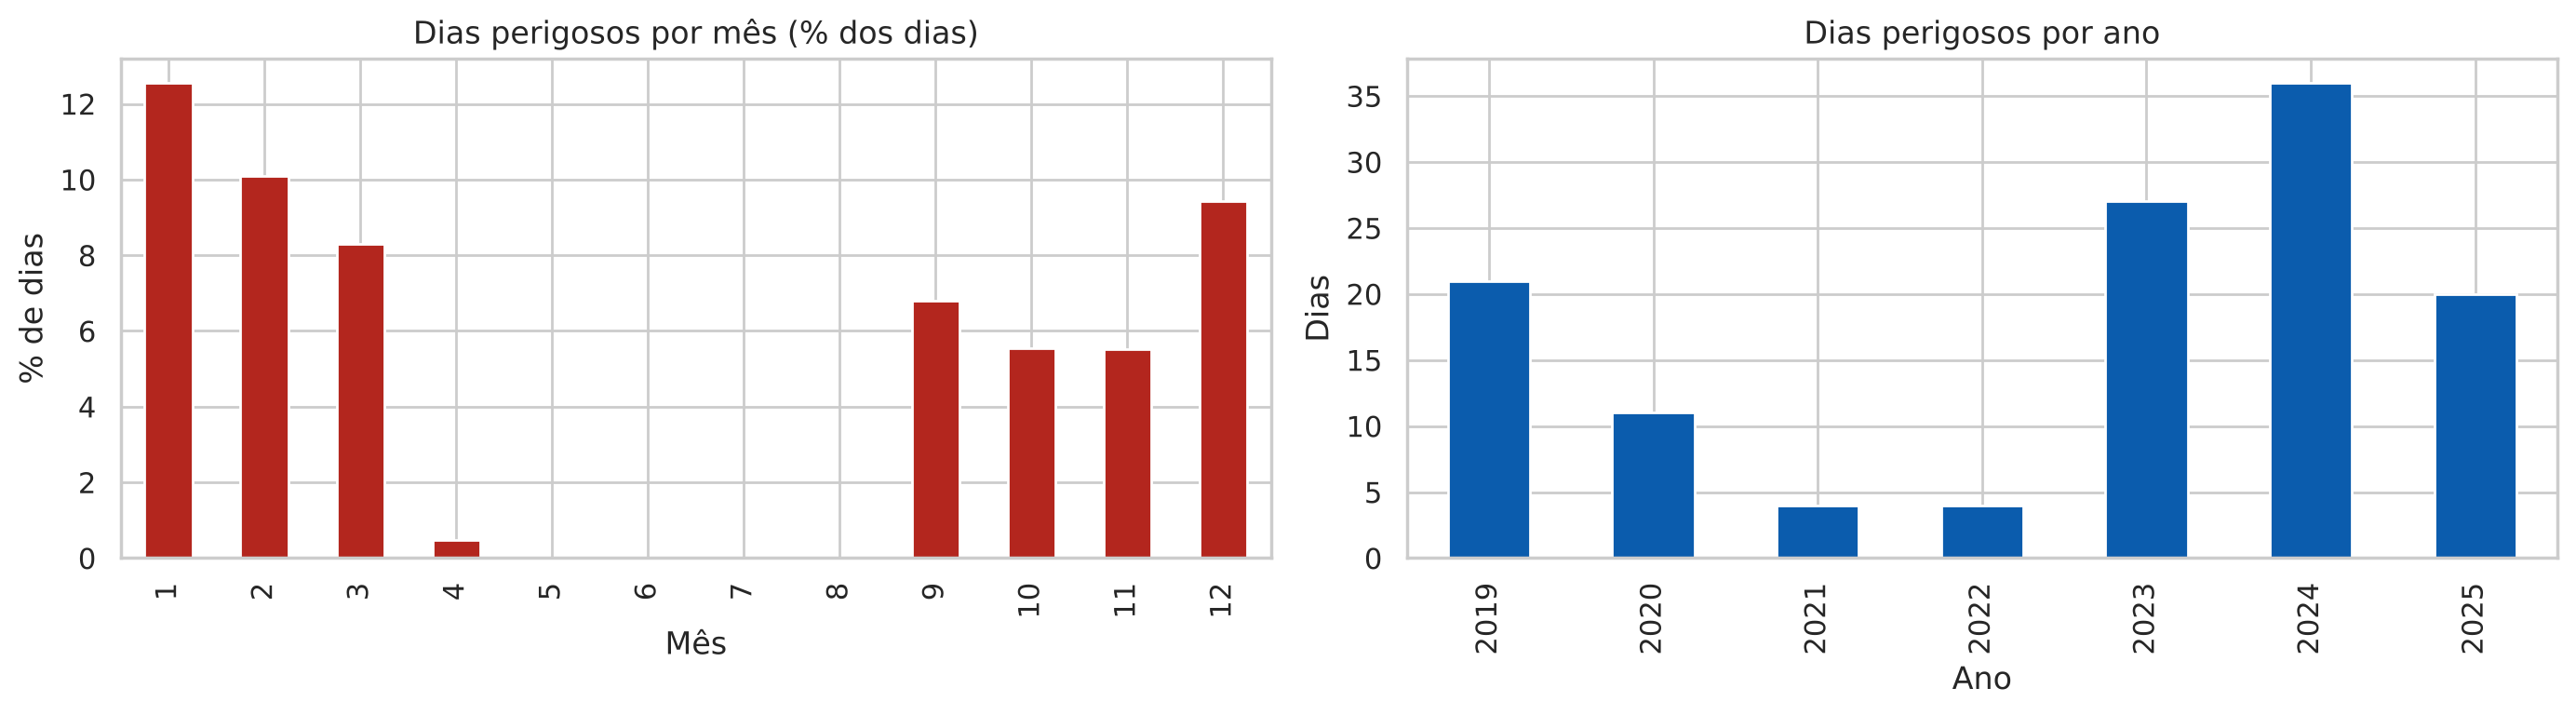

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
mensal = base.assign(mes=base.index.month).groupby("mes")["alvo"].mean().mul(100)
mensal.plot.bar(ax=eixos[0], color="#B3261E")
eixos[0].set(title="Dias perigosos por mês (% dos dias)", xlabel="Mês", ylabel="% de dias")
anual = base.assign(ano=base.index.year).groupby("ano")["alvo"].sum()
anual.plot.bar(ax=eixos[1], color="#0B5CAD")
eixos[1].set(title="Dias perigosos por ano", xlabel="Ano", ylabel="Dias")
plt.tight_layout()
plt.show()

## 5. Divisão treino e teste

Em séries temporais, sortear dias para o teste vaza informação: o modelo veria o dia seguinte e o anterior de cada dia de teste. Por isso a divisão é **pelo tempo**: os dois últimos anos completos da base ficam para o teste, e todo o resto para o treino.

In [8]:
ultimo_ano = base.index.year.max()
inicio_teste = pd.Timestamp(f"{ultimo_ano - 1}-01-01")

treino = base[base.index < inicio_teste]
teste = base[base.index >= inicio_teste]
X_treino, y_treino = treino[VARIAVEIS], treino["alvo"]
X_teste, y_teste = teste[VARIAVEIS], teste["alvo"]

resumo_divisao = pd.DataFrame({
    "período": [f"{treino.index.min():%d/%m/%Y} a {treino.index.max():%d/%m/%Y}", f"{teste.index.min():%d/%m/%Y} a {teste.index.max():%d/%m/%Y}"],
    "dias": [len(treino), len(teste)],
    "dias perigosos": [int(y_treino.sum()), int(y_teste.sum())],
    "% perigosos": [f"{y_treino.mean():.1%}", f"{y_teste.mean():.1%}"],
}, index=["treino", "teste"])
resumo_divisao

,período,dias,dias perigosos,% perigosos
treino,03/01/2019 a 31/12/2023,1785,67,3.8%
teste,01/01/2024 a 30/12/2025,722,56,7.8%


## 6. Modelo e busca de hiperparâmetros

**Modelo escolhido: XGBoost.**

- Os dados são tabulares, com poucas dezenas de variáveis, e o XGBoost costuma ser o modelo mais forte nesse cenário.
- Captura relações não lineares, como "umidade alta só pesa quando a temperatura também está alta", sem precisar normalizar os dados.
- Lida com classes desbalanceadas pelo parâmetro `scale_pos_weight`, que dá mais peso aos poucos dias perigosos.
- Mostra quais variáveis mais pesaram, o que ajuda a explicar o resultado.

**Busca:** 4 × 3 × 2 × 2 = **48 combinações** dos 3 hiperparâmetros principais, mais o peso da classe rara:

| Hiperparâmetro | O que controla | Valores |
| --- | --- | --- |
| `max_depth` | Profundidade de cada árvore (complexidade) | 2, 3, 4, 6 |
| `learning_rate` | Quanto cada árvore nova corrige as anteriores | 0,03; 0,1; 0,3 |
| `n_estimators` | Quantidade de árvores | 100, 300 |
| `scale_pos_weight` | Peso dos dias perigosos | proporção total ou sua raiz quadrada |

O peso total (proporção de dias normais por dias perigosos) compensa o desbalanceamento por completo, mas costuma gerar alarmes demais. A raiz quadrada é um meio-termo comum. Em vez de escolher na mão, deixamos a validação cruzada decidir.

**Validação cruzada só no treino**, com `TimeSeriesSplit` em **3 partes**: cada parte valida num período posterior ao que treinou, imitando o uso real. Com 5 partes, algumas validações caíam em períodos de cerca de 300 dias sem nenhum dia perigoso, e as métricas ficavam indefinidas. Com 3, cada validação cobre mais de um ano e inclui pelo menos um verão.

**Métrica de escolha: PR AUC (precisão média).** A acurácia engana com classes raras: um modelo que sempre diz "não perigoso" acerta 95% dos dias e não serve para nada. A PR AUC mede quão bem o modelo coloca os dias perigosos no topo da lista de probabilidades, sem depender de um limiar fixo. O limiar do alerta é escolhido depois, na seção 6.1.

In [9]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

proporcao = (y_treino == 0).sum() / max((y_treino == 1).sum(), 1)
pesos = [round(float(proporcao), 2), round(float(np.sqrt(proporcao)), 2)]
print(f"Proporção de dias normais por dia perigoso no treino: {proporcao:.1f} | pesos testados: {pesos}")

modelo_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=SEMENTE,
    n_jobs=-1,
)

grade = {
    "max_depth": [2, 3, 4, 6],
    "learning_rate": [0.03, 0.1, 0.3],
    "n_estimators": [100, 300],
    "scale_pos_weight": pesos,
}

validacao = TimeSeriesSplit(n_splits=3)
print("Dias perigosos em cada validação:", [int(y_treino.iloc[v].sum()) for _, v in validacao.split(X_treino)])

busca = GridSearchCV(
    modelo_base,
    grade,
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precisao": "precision"},
    refit="pr_auc",
    cv=validacao,
    return_train_score=True,
    n_jobs=-1,
)
busca.fit(X_treino, y_treino)

resultados = pd.DataFrame(busca.cv_results_)
tabela_busca = (
    resultados[[
        "param_max_depth", "param_learning_rate", "param_n_estimators", "param_scale_pos_weight",
        "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc", "mean_test_f1", "mean_test_recall",
    ]]
    .rename(columns={
        "param_max_depth": "max_depth", "param_learning_rate": "learning_rate", "param_n_estimators": "n_estimators",
        "param_scale_pos_weight": "scale_pos_weight",
        "mean_train_pr_auc": "PR AUC treino (CV)", "mean_test_pr_auc": "PR AUC validação (CV)", "std_test_pr_auc": "desvio PR AUC val.",
        "mean_test_roc_auc": "ROC AUC val.", "mean_test_f1": "F1 val. (limiar 0,5)", "mean_test_recall": "recall val. (limiar 0,5)",
    })
    .sort_values("PR AUC validação (CV)", ascending=False)
    .reset_index(drop=True)
)
tabela_busca.index += 1
print("Melhor combinação:", busca.best_params_)
tabela_busca.round(3)

Proporção de dias normais por dia perigoso no treino: 25.6 | pesos testados: [25.64, 5.06]
Dias perigosos em cada validação: [8, 7, 27]


Melhor combinação: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100, 'scale_pos_weight': 5.06}


,max_depth,learning_rate,n_estimators,scale_pos_weight,PR AUC treino (CV),PR AUC validação (CV),desvio PR AUC val.,ROC AUC val.,"F1 val. (limiar 0,5)","recall val. (limiar 0,5)"
1,2,0.03,100,5.06,0.756,0.302,0.175,0.906,0.284,0.273
2,3,0.03,100,5.06,0.938,0.296,0.161,0.910,0.242,0.211
3,6,0.10,100,5.06,1.000,0.292,0.136,0.898,0.129,0.085
4,2,0.03,100,25.64,0.706,0.289,0.194,0.885,0.292,0.647
5,6,0.03,300,5.06,1.000,0.289,0.156,0.908,0.110,0.072
6,4,0.03,100,5.06,0.996,0.289,0.149,0.917,0.210,0.163
7,2,0.03,300,25.64,0.939,0.284,0.178,0.882,0.285,0.393
8,4,0.03,300,5.06,1.000,0.284,0.137,0.909,0.147,0.097
9,3,0.03,300,5.06,1.000,0.282,0.150,0.896,0.154,0.109
10,6,0.03,300,25.64,1.000,0.277,0.152,0.894,0.225,0.176


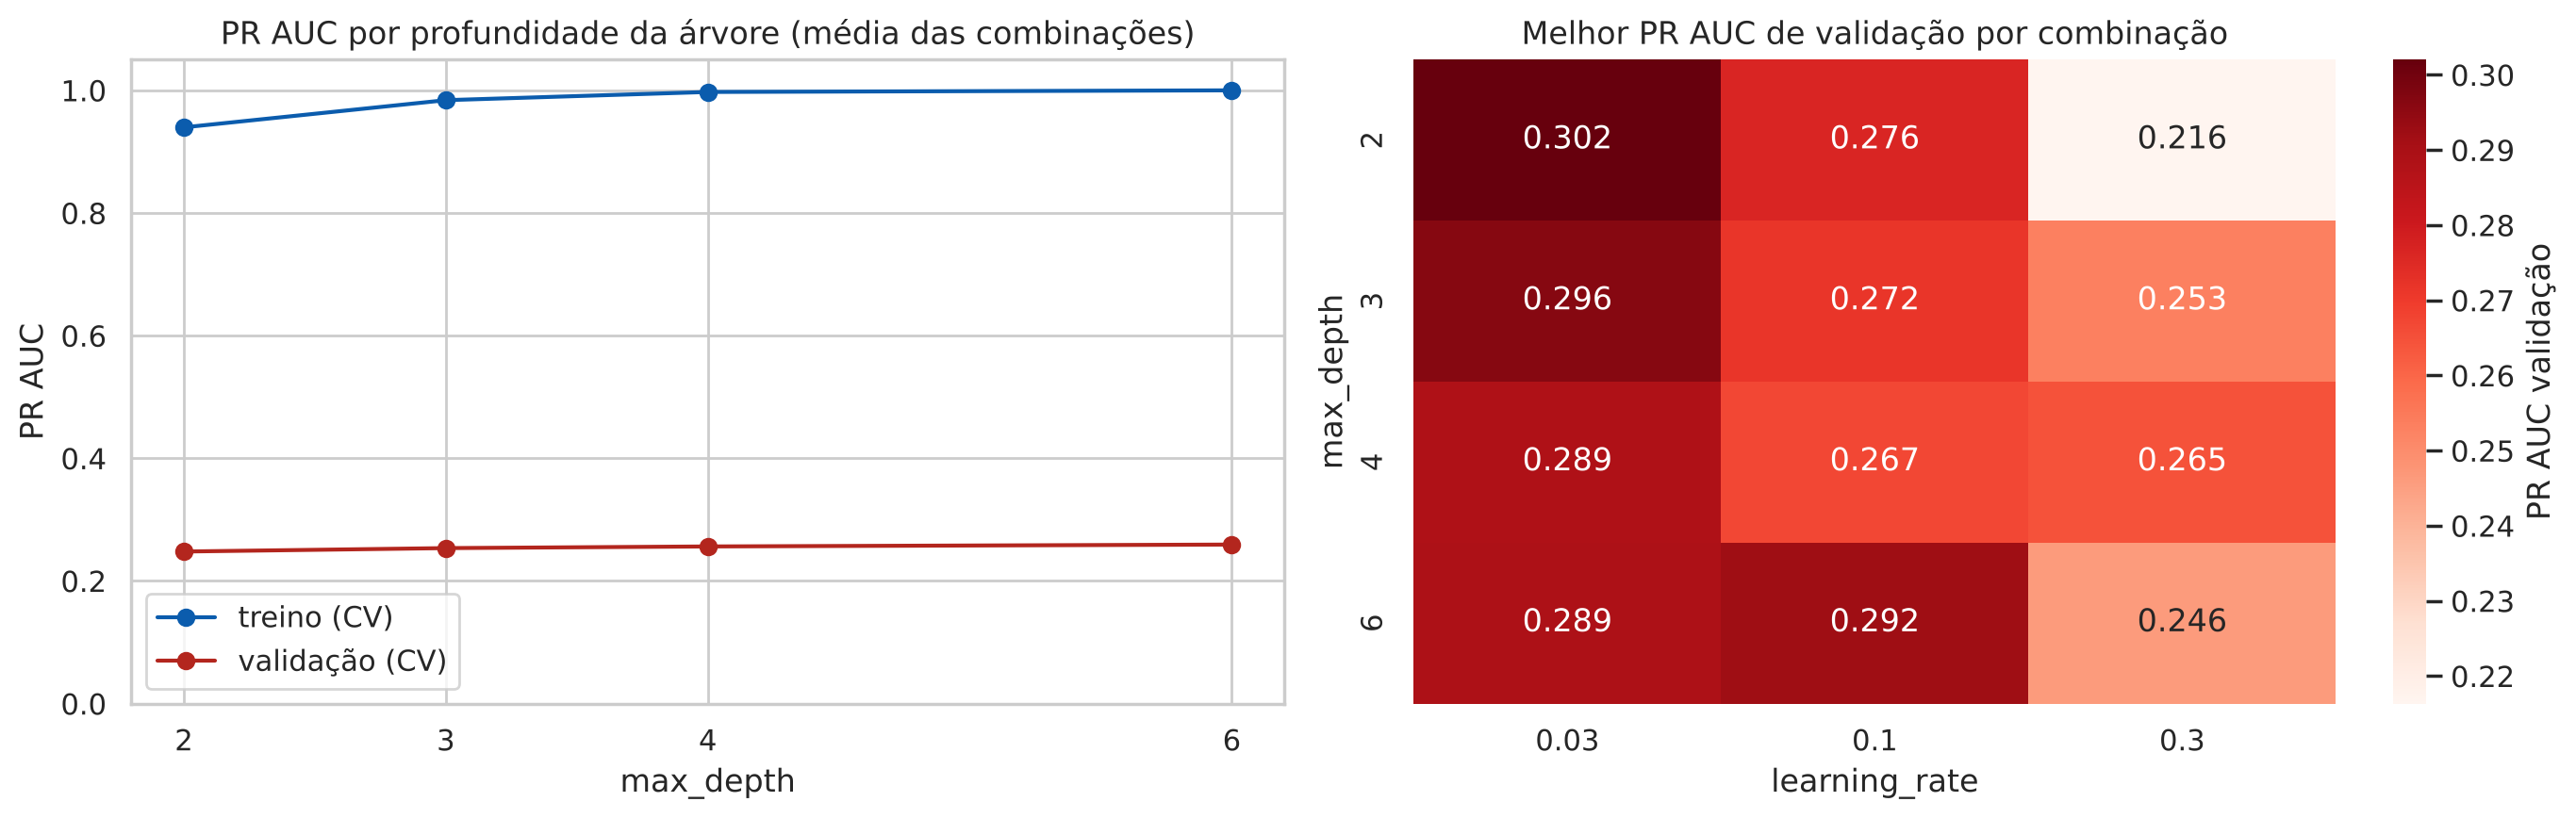

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))

curva = resultados.groupby("param_max_depth")[["mean_train_pr_auc", "mean_test_pr_auc"]].mean()
eixos[0].plot(curva.index, curva["mean_train_pr_auc"], "o-", label="treino (CV)", color="#0B5CAD")
eixos[0].plot(curva.index, curva["mean_test_pr_auc"], "o-", label="validação (CV)", color="#B3261E")
eixos[0].set(title="PR AUC por profundidade da árvore (média das combinações)", xlabel="max_depth", ylabel="PR AUC", ylim=(0, 1.05), xticks=list(curva.index))
eixos[0].legend()

mapa = resultados.pivot_table(index="param_max_depth", columns="param_learning_rate", values="mean_test_pr_auc", aggfunc="max")
sns.heatmap(mapa, annot=True, fmt=".3f", cmap="Reds", ax=eixos[1], cbar_kws={"label": "PR AUC validação"})
eixos[1].set(title="Melhor PR AUC de validação por combinação", xlabel="learning_rate", ylabel="max_depth")
plt.tight_layout()
plt.show()

O gráfico da esquerda é o principal sinal de overfitting: a linha do treino chega perto de 1 com árvores profundas, enquanto a da validação para de subir ou cai. Árvores mais profundas decoram o treino em vez de aprender um padrão geral, e por isso a busca prefere árvores rasas.

### 6.1 Limiar do alerta

O modelo devolve uma probabilidade. Para virar alerta, é preciso um limiar: acima dele, a Refresca avisa o trabalhador. O padrão de 0,5 não tem nada de especial, ainda mais com classes raras.

O limiar é escolhido **só com o treino**: para cada parte da validação cruzada, o modelo treina no passado e prevê o período seguinte. Juntamos essas previsões e escolhemos o limiar com o maior F1. O teste continua intocado.

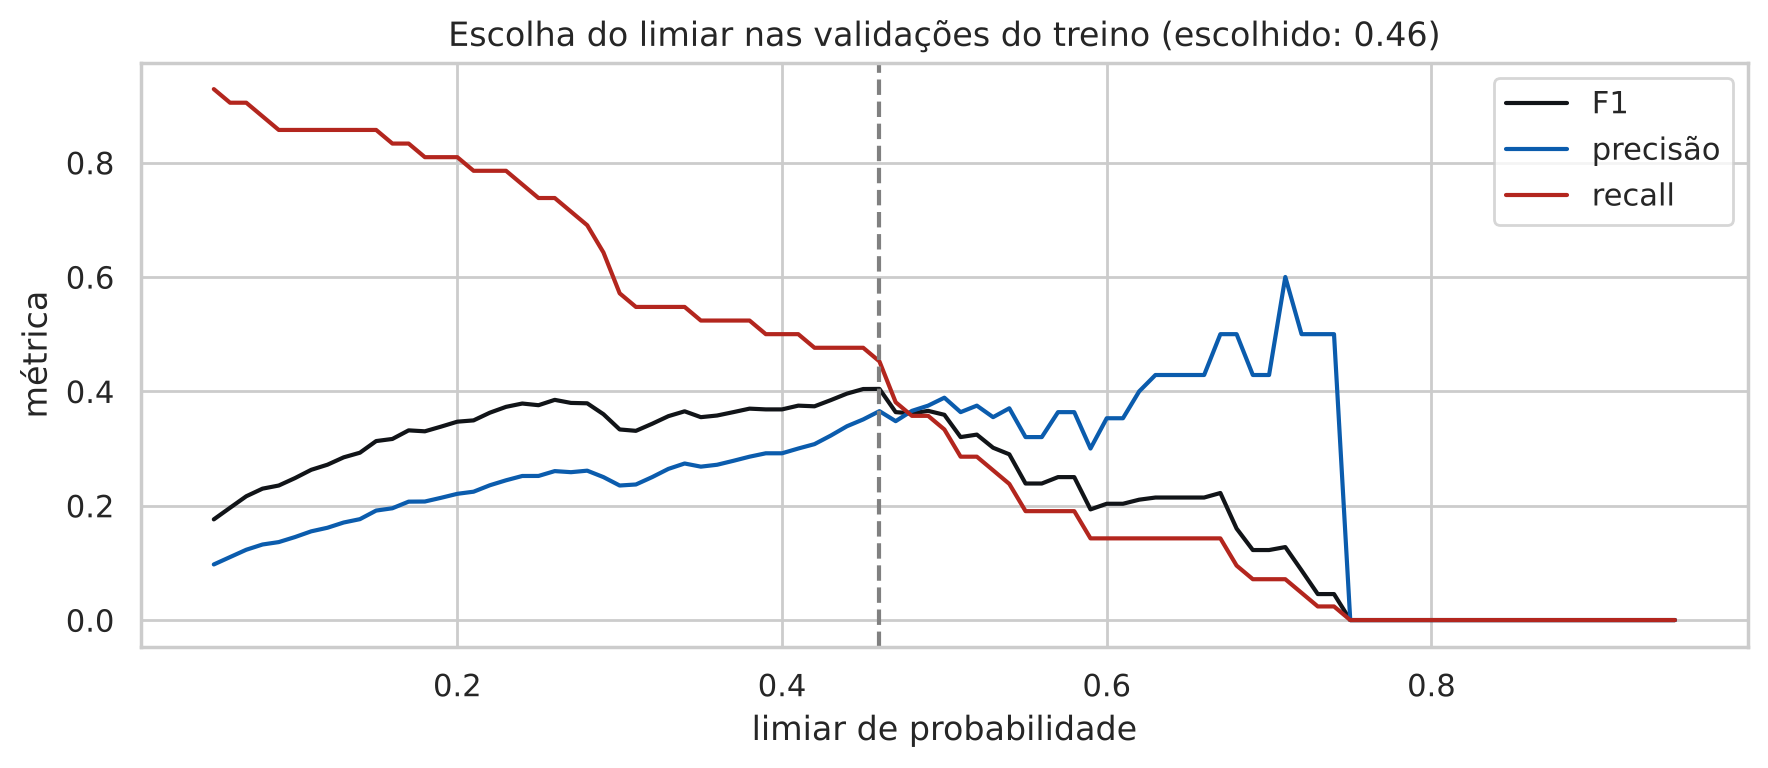

Limiar escolhido: 0.46 (F1 nas validações do treino = 0.404)


In [11]:
params_modelo = {**modelo_base.get_params(), **busca.best_params_}
probs_validacao, reais_validacao = [], []
for idx_treino, idx_val in validacao.split(X_treino):
    m = XGBClassifier(**params_modelo).fit(X_treino.iloc[idx_treino], y_treino.iloc[idx_treino])
    probs_validacao.append(m.predict_proba(X_treino.iloc[idx_val])[:, 1])
    reais_validacao.append(y_treino.iloc[idx_val].to_numpy())
probs_validacao = np.concatenate(probs_validacao)
reais_validacao = np.concatenate(reais_validacao)

limiares = np.round(np.arange(0.05, 0.96, 0.01), 2)
curva_limiar = pd.DataFrame({
    "limiar": limiares,
    "F1": [f1_score(reais_validacao, probs_validacao >= t, zero_division=0) for t in limiares],
    "precisão": [precision_score(reais_validacao, probs_validacao >= t, zero_division=0) for t in limiares],
    "recall": [recall_score(reais_validacao, probs_validacao >= t, zero_division=0) for t in limiares],
})
LIMIAR = float(curva_limiar.loc[curva_limiar["F1"].idxmax(), "limiar"])

ax = curva_limiar.plot(x="limiar", y=["F1", "precisão", "recall"], figsize=(9, 4), color=["#111418", "#0B5CAD", "#B3261E"])
ax.axvline(LIMIAR, ls="--", color="gray")
ax.set(title=f"Escolha do limiar nas validações do treino (escolhido: {LIMIAR:.2f})", xlabel="limiar de probabilidade", ylabel="métrica")
plt.tight_layout()
plt.show()
print(f"Limiar escolhido: {LIMIAR:.2f} (F1 nas validações do treino = {curva_limiar['F1'].max():.3f})")

## 7. Resultados em treino e teste

O melhor modelo da busca, treinado com todo o período de treino, é avaliado uma única vez no teste, que ficou guardado até aqui, usando o limiar da seção 6.1.

Também comparamos com uma **regra simples de referência**: "amanhã será perigoso se hoje foi perigoso". Como as ondas de calor duram vários dias, essa regra é difícil de bater e serve de régua honesta para o modelo.

Além do F1, mostramos o **F2**, que pesa o recall duas vezes mais que a precisão. Para o trabalhador de rua, deixar passar um dia perigoso custa mais caro do que um alarme falso, que no máximo o faz levar uma garrafa de água a mais.

In [12]:
modelo = busca.best_estimator_


def metricas(y_real, y_prev, prob):
    return {
        "acurácia": accuracy_score(y_real, y_prev),
        "precisão": precision_score(y_real, y_prev, zero_division=0),
        "recall": recall_score(y_real, y_prev, zero_division=0),
        "F1": f1_score(y_real, y_prev, zero_division=0),
        "F2": fbeta_score(y_real, y_prev, beta=2, zero_division=0),
        "ROC AUC": roc_auc_score(y_real, prob) if len(set(y_real)) > 1 else np.nan,
        "PR AUC": average_precision_score(y_real, prob) if len(set(y_real)) > 1 else np.nan,
        "alertas emitidos": int(np.sum(y_prev)),
    }


prob_treino = modelo.predict_proba(X_treino)[:, 1]
prob_teste = modelo.predict_proba(X_teste)[:, 1]
prev_treino = (prob_treino >= LIMIAR).astype(int)
prev_teste = (prob_teste >= LIMIAR).astype(int)

referencia_teste = X_teste["perigoso_hoje"].astype(int)

comparacao = pd.DataFrame({
    "treino": metricas(y_treino, prev_treino, prob_treino),
    "teste": metricas(y_teste, prev_teste, prob_teste),
    "referência no teste (hoje = amanhã)": metricas(y_teste, referencia_teste, referencia_teste),
}).round(3)
comparacao["diferença treino − teste"] = (comparacao["treino"] - comparacao["teste"]).round(3)
comparacao.loc["alertas emitidos", "diferença treino − teste"] = np.nan
comparacao

,treino,teste,referência no teste (hoje = amanhã),diferença treino − teste
acurácia,0.954,0.910,0.929,0.044
precisão,0.439,0.446,0.545,-0.007
recall,0.806,0.661,0.536,0.145
F1,0.568,0.532,0.541,0.036
F2,0.691,0.603,0.538,0.088
ROC AUC,0.975,0.911,0.749,0.064
PR AUC,0.642,0.463,0.328,0.179
alertas emitidos,123.000,83.000,55.000,NaN


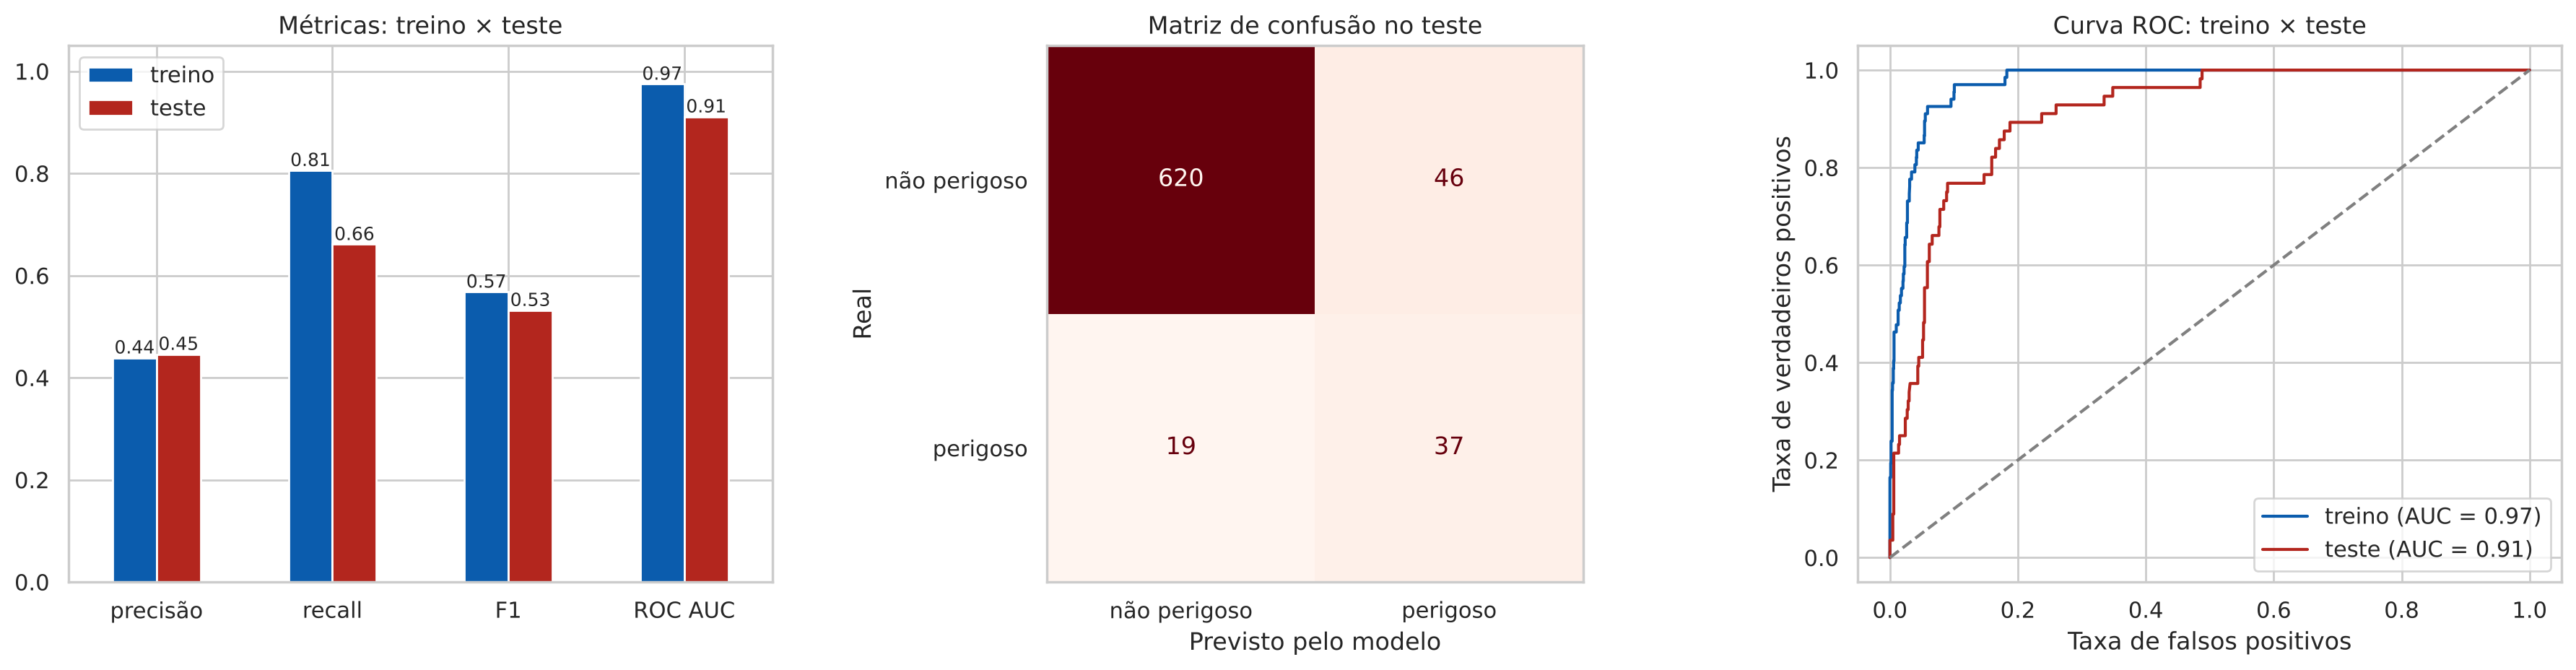

In [13]:
fig, eixos = plt.subplots(1, 3, figsize=(18, 4.8))

comparacao[["treino", "teste"]].loc[["precisão", "recall", "F1", "ROC AUC"]].plot.bar(
    ax=eixos[0], color=["#0B5CAD", "#B3261E"], rot=0
)
eixos[0].set(title="Métricas: treino × teste", ylim=(0, 1.05))
for barra in eixos[0].containers:
    eixos[0].bar_label(barra, fmt="%.2f", fontsize=9)

ConfusionMatrixDisplay.from_predictions(
    y_teste, prev_teste, display_labels=["não perigoso", "perigoso"], cmap="Reds", ax=eixos[1], colorbar=False
)
eixos[1].set(title="Matriz de confusão no teste", xlabel="Previsto pelo modelo", ylabel="Real")
eixos[1].grid(False)

for nome, y_real, prob, cor in [("treino", y_treino, prob_treino, "#0B5CAD"), ("teste", y_teste, prob_teste, "#B3261E")]:
    fpr, tpr, _ = roc_curve(y_real, prob)
    eixos[2].plot(fpr, tpr, color=cor, label=f"{nome} (AUC = {roc_auc_score(y_real, prob):.2f})")
eixos[2].plot([0, 1], [0, 1], "--", color="gray")
eixos[2].set(title="Curva ROC: treino × teste", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
eixos[2].legend()
plt.tight_layout()
plt.show()

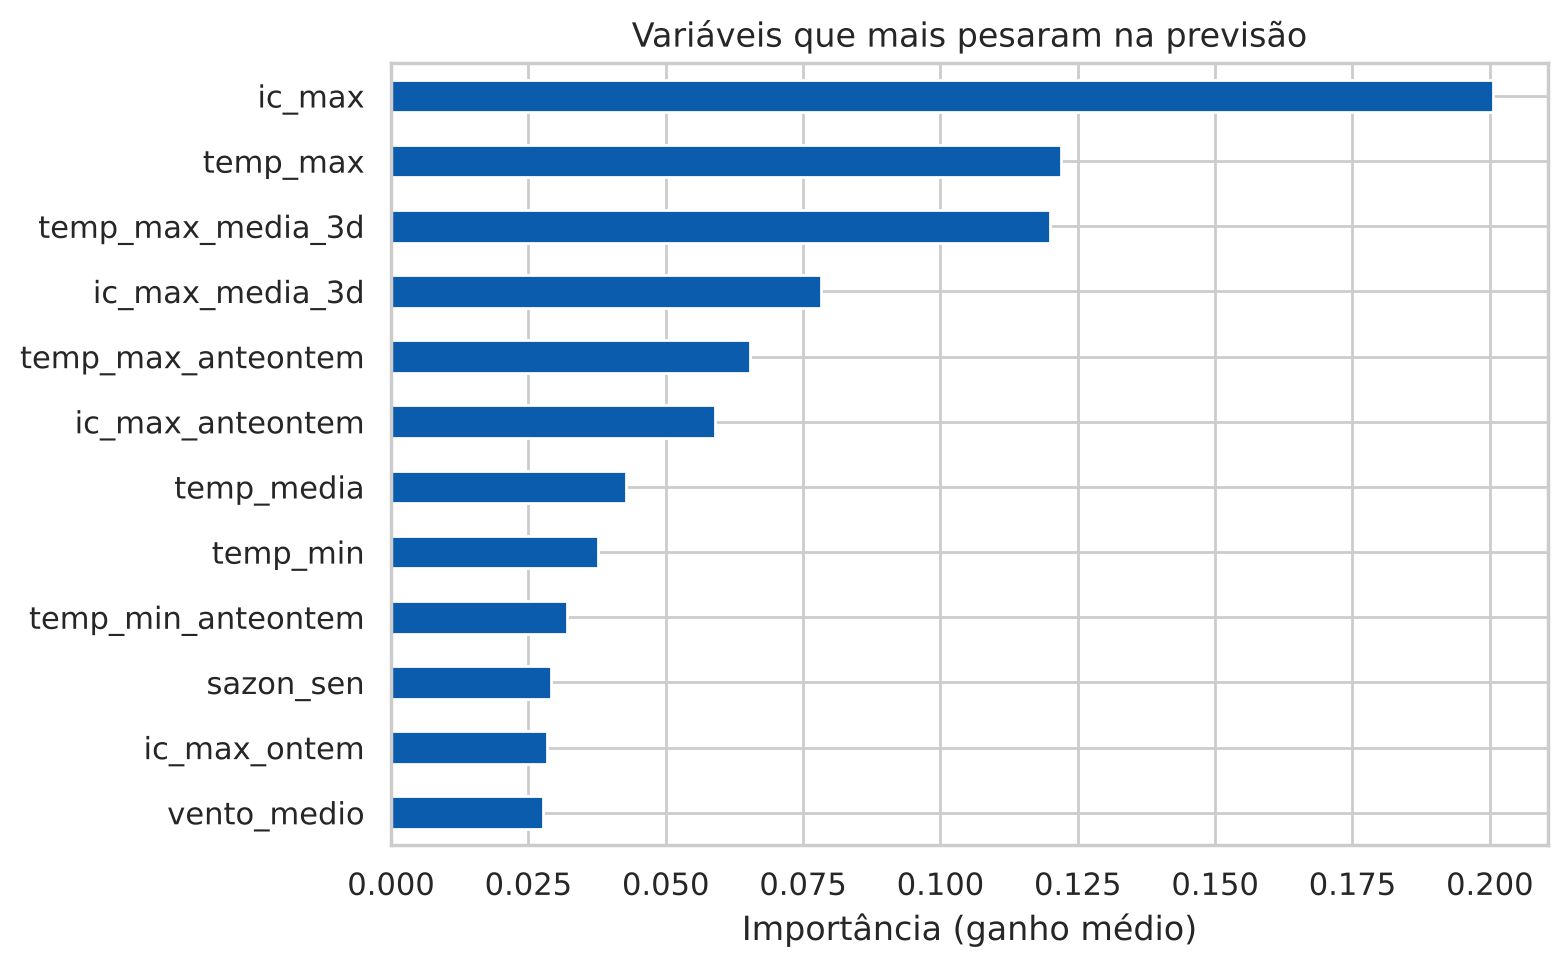

In [14]:
importancias = pd.Series(modelo.feature_importances_, index=VARIAVEIS).sort_values().tail(12)
importancias.plot.barh(figsize=(8, 5), color="#0B5CAD")
plt.title("Variáveis que mais pesaram na previsão")
plt.xlabel("Importância (ganho médio)")
plt.tight_layout()
plt.show()

In [15]:
pr_treino, pr_teste = comparacao.loc["PR AUC", "treino"], comparacao.loc["PR AUC", "teste"]
roc_treino, roc_teste = comparacao.loc["ROC AUC", "treino"], comparacao.loc["ROC AUC", "teste"]
gap = pr_treino - pr_teste
if gap > 0.25:
    leitura = "há sinal claro de overfitting: o modelo separa os dias perigosos bem melhor no treino do que em dias que nunca viu"
elif gap > 0.08:
    leitura = "há um overfitting moderado, esperado com tão poucos dias perigosos no treino, mas o modelo mantém boa capacidade de separar os dias no teste"
else:
    leitura = "não há sinal relevante de overfitting: o desempenho no teste é parecido com o do treino"
print(f"PR AUC treino = {pr_treino:.3f} | teste = {pr_teste:.3f} | diferença = {gap:.3f}")
print(f"ROC AUC treino = {roc_treino:.3f} | teste = {roc_teste:.3f}")
print(f"Leitura: {leitura}.")
print()
print(f"Dias perigosos: {y_treino.mean():.1%} dos dias no treino (2019-2023) e {y_teste.mean():.1%} no teste (2024-2025).")

PR AUC treino = 0.642 | teste = 0.463 | diferença = 0.179
ROC AUC treino = 0.975 | teste = 0.911
Leitura: há um overfitting moderado, esperado com tão poucos dias perigosos no treino, mas o modelo mantém boa capacidade de separar os dias no teste.

Dias perigosos: 3.8% dos dias no treino (2019-2023) e 7.8% no teste (2024-2025).


## 8. Conclusão para o cidadão

A célula abaixo traduz as métricas do teste para a linguagem do trabalhador de rua.

In [16]:
def resumo(prev):
    vp = int(((prev == 1) & (y_teste == 1)).sum())
    fn = int(((prev == 0) & (y_teste == 1)).sum())
    fp = int(((prev == 1) & (y_teste == 0)).sum())
    return vp, fn, fp

vp, fn, fp = resumo(prev_teste)
rvp, rfn, rfp = resumo(referencia_teste.to_numpy())
total = vp + fn

print(f"No período de teste (2024 e 2025) houve {total} dias de calor perigoso.")
print()
print(f"Modelo Refresca: avisou na véspera em {vp} deles ({vp / total:.0%}) e deixou passar {fn}.")
print(f"                 emitiu {vp + fp} alertas, dos quais {fp} foram alarmes falsos ({fp / max(vp + fp, 1):.0%}).")
print(f"Regra 'amanhã = hoje': avisaria em {rvp} ({rvp / total:.0%}) e deixaria passar {rfn}.")
print(f"                 emitiria {rvp + rfp} alertas, dos quais {rfp} falsos ({rfp / max(rvp + rfp, 1):.0%}).")
print()
ic_dia_seguinte = dados["ic_max"].shift(-1).loc[X_teste.index]
falsos = (prev_teste == 1) & (y_teste.to_numpy() == 0)
quase = int((ic_dia_seguinte[falsos] >= 30).sum())
print(f"Nos {int(falsos.sum())} alarmes falsos, o índice de calor do dia seguinte ficou em {ic_dia_seguinte[falsos].median():.1f} °C (mediana);")
print(f"em {quase} deles chegou a 30 °C ou mais, ou seja, o dia foi quente, só não passou do limite de perigo.")
print()
print(f"Para o trabalhador: em cada 10 dias de calor perigoso, a Refresca avisaria na véspera em cerca de {round(10 * vp / total)};")
print(f"a regra simples avisaria em cerca de {round(10 * rvp / total)}.")

No período de teste (2024 e 2025) houve 56 dias de calor perigoso.

Modelo Refresca: avisou na véspera em 37 deles (66%) e deixou passar 19.
                 emitiu 83 alertas, dos quais 46 foram alarmes falsos (55%).
Regra 'amanhã = hoje': avisaria em 30 (54%) e deixaria passar 26.
                 emitiria 55 alertas, dos quais 25 falsos (45%).

Nos 46 alarmes falsos, o índice de calor do dia seguinte ficou em 31.1 °C (mediana);
em 36 deles chegou a 30 °C ou mais, ou seja, o dia foi quente, só não passou do limite de perigo.

Para o trabalhador: em cada 10 dias de calor perigoso, a Refresca avisaria na véspera em cerca de 7;
a regra simples avisaria em cerca de 5.


## 9. Salvar o modelo para o serviço de previsão

O modelo treinado vai para `modelo/` em dois formatos: `.joblib` (para uso em Python com scikit-learn) e `.json` (formato nativo do XGBoost, usado pelo serviço de previsão do repositório de SOA). O `metadados.json` guarda a ordem das variáveis, o limiar do alerta e as métricas.

**Atenção às versões:** o mesmo arquivo de modelo dá probabilidades diferentes em versões diferentes do XGBoost. Testamos: o mesmo dia quente dá 0,70 no XGBoost 3.4.1 e 0,90 no 3.0.5. Por isso o `requirements.txt` fixa as versões exatas usadas aqui.

In [17]:
PASTA_MODELO = Path("modelo")
PASTA_MODELO.mkdir(exist_ok=True)
joblib.dump(modelo, PASTA_MODELO / "modelo_refresca.joblib")
# Formato nativo do XGBoost, usado pelo serviço de previsão (não depende do scikit-learn)
modelo.get_booster().save_model(PASTA_MODELO / "modelo_refresca.json")

metadados = {
    "versao": "1.0",
    "xgboost": xgboost.__version__,
    "scikit_learn": sklearn.__version__,
    "estacao": ESTACAO,
    "periodo_dados": f"{base.index.min():%Y-%m-%d} a {base.index.max():%Y-%m-%d}",
    "limite_perigo_indice_calor_c": LIMITE_PERIGO,
    "limiar_alerta": LIMIAR,
    "variaveis": VARIAVEIS,
    "melhores_hiperparametros": {k: (v.item() if hasattr(v, "item") else v) for k, v in busca.best_params_.items()},
    "metricas_teste": {k: round(float(v), 4) for k, v in comparacao["teste"].items()},
    "metricas_treino": {k: round(float(v), 4) for k, v in comparacao["treino"].items()},
}
(PASTA_MODELO / "metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(metadados, ensure_ascii=False, indent=2))

{
  "versao": "1.0",
  "xgboost": "3.4.1",
  "scikit_learn": "1.9.1",
  "estacao": "A701",
  "periodo_dados": "2019-01-03 a 2025-12-30",
  "limite_perigo_indice_calor_c": 32.0,
  "limiar_alerta": 0.46,
  "variaveis": [
    "temp_max",
    "temp_min",
    "temp_media",
    "umid_media",
    "umid_min",
    "ic_max",
    "pressao_media",
    "radiacao_total",
    "precip_total",
    "vento_medio",
    "perigoso_hoje",
    "temp_max_ontem",
    "temp_max_anteontem",
    "ic_max_ontem",
    "ic_max_anteontem",
    "umid_media_ontem",
    "umid_media_anteontem",
    "temp_min_ontem",
    "temp_min_anteontem",
    "temp_max_media_3d",
    "ic_max_media_3d",
    "dias_perigosos_3d",
    "var_pressao",
    "var_temp_max",
    "sazon_sen",
    "sazon_cos"
  ],
  "melhores_hiperparametros": {
    "learning_rate": 0.03,
    "max_depth": 2,
    "n_estimators": 100,
    "scale_pos_weight": 5.06
  },
  "metricas_teste": {
    "acurácia": 0.91,
    "precisão": 0.446,
    "recall": 0.661,
    "F1": 0.

## 10. Conferência com o módulo do serviço de previsão

O serviço de previsão não roda este notebook: ele usa o módulo `preparar_variaveis.py`, que monta as mesmas variáveis a partir do resumo de 3 dias enviado pela API. A célula abaixo confere, em todos os dias do teste, que o módulo e o notebook calculam exatamente os mesmos valores.

In [18]:
from preparar_variaveis import CAMPOS_DIA, como_linha, montar_variaveis

nome_para_json = {v: k for k, v in CAMPOS_DIA.items()}
divergencias = 0
for dia_hoje in teste.index:
    tres_dias = []
    for d in [dia_hoje - pd.Timedelta(days=2), dia_hoje - pd.Timedelta(days=1), dia_hoje]:
        linha = dados.loc[d]
        tres_dias.append({"dia": d.date().isoformat(), **{nome_para_json[c]: float(linha[c]) for c in CAMPOS_DIA.values()}})
    do_modulo = como_linha(montar_variaveis(tres_dias), VARIAVEIS)
    do_notebook = X_teste.loc[[dia_hoje], VARIAVEIS].reset_index(drop=True)
    if not np.allclose(do_modulo.to_numpy(dtype=float), do_notebook.to_numpy(dtype=float)):
        divergencias += 1

print(f"{len(teste)} dias conferidos, {divergencias} divergência(s).")
assert divergencias == 0

722 dias conferidos, 0 divergência(s).
